# Préparation des données SINERT — phase 1 (Kaggle)

Dans Kaggle, ajoute comme **Input** le dataset SINERT (archive ZIP ou dossier de CSV/XLSX). Ajoute aussi `pipeline.py` comme Input (par exemple dans un petit dataset Kaggle privé contenant ce fichier). Les Inputs Kaggle sont en lecture seule; les résultats seront écrits dans `/kaggle/working/phase1`.

Le pipeline lit directement les CSV/XLSX d'un ZIP sans extraire l'archive, ou parcourt un dossier déjà extrait. Si plusieurs archives sont trouvées, choisis explicitement celle à traiter dans la cellule de configuration.

In [ ]:
from pathlib import Path
import os

KAGGLE_INPUT = Path('/kaggle/input')
OUTPUT_DIR = Path('/kaggle/working/phase1')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not KAGGLE_INPUT.exists():
    raise RuntimeError('Cette cellule doit être exécutée dans un notebook Kaggle.')

archives = sorted(KAGGLE_INPUT.rglob('*.zip'))
exports = sorted(path for path in KAGGLE_INPUT.rglob('*')
                 if path.is_file() and path.suffix.casefold() in {'.csv', '.xlsx'})
pipeline_files = sorted(KAGGLE_INPUT.rglob('pipeline.py'))
print('Archives ZIP trouvées :')
for path in archives:
    print(f'  {path}')
print('\npipeline.py trouvé :')
for path in pipeline_files:
    print(f'  {path}')

if not pipeline_files:
    raise FileNotFoundError(
        'Ajoute pipeline.py comme Input Kaggle (dataset de code), puis relance.'
    )
PIPELINE = pipeline_files[0]
if len(archives) > 1:
    raise RuntimeError('Plusieurs ZIP trouvés : sélectionne explicitement celui voulu.')
if archives:
    DATA_SOURCE = archives[0]
elif exports:
    # Trouve le dossier commun des exports : cela fonctionne aussi avec un dataset déjà extrait.
    DATA_SOURCE = Path(os.path.commonpath([str(path.parent) for path in exports]))
else:
    raise FileNotFoundError('Aucun ZIP, CSV ou XLSX trouvé sous /kaggle/input.')

print('\nPipeline :', PIPELINE)
print('Données :', DATA_SOURCE)
print('Sortie :', OUTPUT_DIR)

## Dépendances

Kaggle fournit souvent pandas et numpy préinstallés. Cette cellule n'installe que les modules manquants nécessaires aux exports XLSX et Parquet.

In [ ]:
import importlib.util
import subprocess
import sys

required = {'openpyxl': 'openpyxl', 'pyarrow': 'pyarrow<19'}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)
else:
    print('Dépendances déjà disponibles.')

## Paramètres et exécution

L'horizon ci-dessous est d'un pas (15 minutes), à confirmer avec les encadrantes. Le jeu fériés peut être ajouté plus tard avec `--holidays`.

In [ ]:
import subprocess
import sys

command = [
    sys.executable, str(PIPELINE),
    '--input', str(DATA_SOURCE),
    '--output', str(OUTPUT_DIR),
    '--meter', 'EM_VIRTUAL',
    '--window-steps', '672',
    '--horizon-steps', '1',
    '--max-short-gap', '4',
]
print('Commande :', ' '.join(command))
subprocess.run(command, check=True)

In [ ]:
import json
import pandas as pd
from IPython.display import display

report_path = OUTPUT_DIR / 'quality_report.json'
report = json.loads(report_path.read_text(encoding='utf-8'))
print(json.dumps(report, ensure_ascii=False, indent=2))

clean = pd.read_parquet(OUTPUT_DIR / 'sinert_clean.parquet')
windows = pd.read_parquet(OUTPUT_DIR / 'window_index.parquet')
print('\nDonnées nettoyées :', clean.shape)
print('Fenêtres :', windows.shape)

physical_columns = report['target_columns']
missing_summary = pd.DataFrame({
    column: {
        'valeurs_manquantes': details['missing_values'],
        'pourcentage': details['missing_percent'],
        'premiere_valeur_valide': details['first_valid_timestamp'],
        'derniere_valeur_valide': details['last_valid_timestamp'],
    }
    for column, details in report['physical_quality_after_imputation'].items()
}).T
print('\nQualité des mesures après imputation :')
display(missing_summary)
print('Lignes comportant au moins une mesure encore manquante :',
      report['rows_with_unresolved_physical_missing'])
print('Lignes où au moins une valeur a été imputée :',
      report['rows_with_any_imputed_physical_value'])
print('\nPlus longues lacunes restantes par variable :')
for column, details in report['physical_quality_after_imputation'].items():
    print(f"\n{column}:")
    display(pd.DataFrame(details['longest_missing_runs']))
print('\nRemarque : une ligne peut être non imputée et rester manquante. '
      'was_imputed indique une valeur synthétique; '
      'has_missing_physical indique une mesure toujours absente.')
display(clean.head())
display(windows.groupby('split').size().rename('nombre_de_fenetres'))

import matplotlib.pyplot as plt

if clean['was_imputed'].any():
    first_imputed = clean.index[clean['was_imputed']][0]
    plot_start = first_imputed - pd.Timedelta(hours=12)
    plot_end = first_imputed + pd.Timedelta(hours=36)
    plot_data = clean.loc[plot_start:plot_end]
    fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)
    for ax, column in zip(axes, physical_columns):
        imputed_column = f'imputed_{column}'
        ax.plot(plot_data.index, plot_data[column], color='steelblue', linewidth=1,
                label='Valeur nettoyée')
        imputed_points = plot_data[imputed_column].fillna(False)
        ax.scatter(plot_data.index[imputed_points], plot_data.loc[imputed_points, column],
                   color='crimson', s=24, label='Valeur imputée', zorder=3)
        ax.set_ylabel(column)
        ax.legend(loc='upper right')
        ax.grid(True, alpha=0.25)
    fig.suptitle(f'Exemple de zones imputées : {plot_start} — {plot_end}')
    fig.tight_layout()
    plt.show()
else:
    print('Aucune valeur imputée : rien à tracer.')

print('\nFichiers livrables :')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path, f'({path.stat().st_size:,} octets)')

In [5]:
from pathlib import Path
import shutil

pipeline_files = list(Path("/kaggle/input").rglob("pipeline.py"))

if not pipeline_files:
    raise FileNotFoundError("pipeline.py est introuvable dans les Inputs Kaggle.")

PIPELINE = pipeline_files[0]
print("Pipeline trouvé :", PIPELINE)

shutil.copy(PIPELINE, "/kaggle/working/pipeline.py")
print("Pipeline copié dans /kaggle/working/pipeline.py")

Pipeline trouvé : /kaggle/input/datasets/haninehamrouni15/sinert-pipeline-code/pipeline.py
Pipeline copié dans /kaggle/working/pipeline.py


In [7]:
from pathlib import Path

data_files = [
    path for path in Path("/kaggle/input").rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".zip", ".csv", ".xlsx"}
]

print("Fichiers de données trouvés :")
for path in data_files:
    print(path)

Fichiers de données trouvés :
/kaggle/input/datasets/haninehamrouni15/supcom-sinert-raw-data/SINERT_DATA_CONCENTRATOR/April2023/2023-04-01_2023-04-02_Daily Report_Main AC meter.csv
/kaggle/input/datasets/haninehamrouni15/supcom-sinert-raw-data/SINERT_DATA_CONCENTRATOR/April2023/2023-04-03_2023-04-04_Daily Report_Main AC meter.csv
/kaggle/input/datasets/haninehamrouni15/supcom-sinert-raw-data/SINERT_DATA_CONCENTRATOR/April2023/2023-04-05_2023-04-06_Daily Report_Main AC meter.csv
/kaggle/input/datasets/haninehamrouni15/supcom-sinert-raw-data/SINERT_DATA_CONCENTRATOR/April2023/2023-04-07_2023-04-08_Daily Report_Main AC meter.csv
/kaggle/input/datasets/haninehamrouni15/supcom-sinert-raw-data/SINERT_DATA_CONCENTRATOR/April2023/2023-04-09_2023-04-10_Daily Report_Main AC meter.csv
/kaggle/input/datasets/haninehamrouni15/supcom-sinert-raw-data/SINERT_DATA_CONCENTRATOR/April2023/2023-04-11_2023-04-12_Daily Report_Main AC meter.csv
/kaggle/input/datasets/haninehamrouni15/supcom-sinert-raw-data/S

In [6]:
from pathlib import Path

print(Path("/kaggle/working/pipeline.py").exists())

True


In [8]:
from pathlib import Path
import subprocess
import sys
import os

# Dossier contenant tous les fichiers SINERT
DATA_SOURCE = Path(
    "/kaggle/input/datasets/haninehamrouni15/"
    "supcom-sinert-raw-data/SINERT_DATA_CONCENTRATOR"
)

# Vérification
if not DATA_SOURCE.exists():
    raise FileNotFoundError(f"Dossier introuvable : {DATA_SOURCE}")

print("Dossier des données :", DATA_SOURCE)

# Dossier de sortie
OUTPUT_DIR = Path("/kaggle/working/phase1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Exécution du pipeline A
command = [
    sys.executable,
    "/kaggle/working/pipeline.py",
    "--input", str(DATA_SOURCE),
    "--output", str(OUTPUT_DIR),
    "--meter", "EM_VIRTUAL",
    "--window-steps", "672",
    "--horizon-steps", "1",
    "--max-short-gap", "4",
]

print("Lancement du pipeline...")
subprocess.run(command, check=True)

print("Pipeline terminé.")

Dossier des données : /kaggle/input/datasets/haninehamrouni15/supcom-sinert-raw-data/SINERT_DATA_CONCENTRATOR
Lancement du pipeline...
Done: 128,737 intervals, 120,835 valid windows. Outputs: /kaggle/working/phase1
Pipeline terminé.


In [9]:
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/phase1")

print("Fichiers générés :")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path)

Fichiers générés :
/kaggle/working/phase1/quality_report.json
/kaggle/working/phase1/sinert_clean.parquet
/kaggle/working/phase1/window_index.parquet


In [10]:
import pandas as pd

clean = pd.read_parquet(
    "/kaggle/working/phase1/sinert_clean.parquet"
)

clean.index = pd.to_datetime(clean.index)
clean = clean.sort_index()

print("Dimensions :", clean.shape)
print("Début :", clean.index.min())
print("Fin :", clean.index.max())

display(clean.head())

Dimensions : (128737, 18)
Début : 2022-06-01 00:00:00
Fin : 2026-02-01 00:00:00


,delta_ea_kwh,delta_er_kvarh,pmax_kw,smax_kva,hour_sin,hour_cos,weekday_sin,weekday_cos,month_sin,month_cos,is_nonworking_day,was_imputed,has_missing_physical,imputed_delta_ea_kwh,imputed_delta_er_kvarh,imputed_pmax_kw,imputed_smax_kva,imputation_future_boundary
timestamp,,,,,,,,,,,,,,,,,,
2022-06-01 00:00:00,<NA>,<NA>,<NA>,<NA>,0.000000,1.000000,0.974928,-0.222521,0.5,-0.866025,0.0,False,True,False,False,False,False,NaT
2022-06-01 00:15:00,<NA>,<NA>,<NA>,<NA>,0.065403,0.997859,0.972805,-0.231627,0.5,-0.866025,0.0,False,True,False,False,False,False,NaT
2022-06-01 00:30:00,<NA>,<NA>,<NA>,<NA>,0.130526,0.991445,0.970597,-0.240712,0.5,-0.866025,0.0,False,True,False,False,False,False,NaT
2022-06-01 00:45:00,<NA>,<NA>,<NA>,<NA>,0.195090,0.980785,0.968304,-0.249776,0.5,-0.866025,0.0,False,True,False,False,False,False,NaT
2022-06-01 01:00:00,<NA>,<NA>,<NA>,<NA>,0.258819,0.965926,0.965926,-0.258819,0.5,-0.866025,0.0,False,True,False,False,False,False,NaT


In [11]:
physical_columns = [
    "delta_ea_kwh",
    "delta_er_kvarh",
    "pmax_kw",
    "smax_kva",
]

print("Valeurs manquantes :")
display(clean[physical_columns].isna().sum())

print("\nPourcentage de valeurs manquantes :")
display(
    clean[physical_columns]
    .isna()
    .mean()
    .mul(100)
    .round(2)
)

print("\nValeurs imputées :")
print(clean["was_imputed"].sum())

print("\nLignes avec valeurs encore manquantes :")
print(clean["has_missing_physical"].sum())

Valeurs manquantes :


delta_ea_kwh      2889
delta_er_kvarh    2889
pmax_kw           2881
smax_kva          2881
dtype: int64


Pourcentage de valeurs manquantes :


delta_ea_kwh      2.24
delta_er_kvarh    2.24
pmax_kw           2.24
smax_kva          2.24
dtype: float64


Valeurs imputées :
3427

Lignes avec valeurs encore manquantes :
2889


In [12]:
time_step = clean.index.to_series().diff()

print("Pas temporels principaux :")
display(time_step.value_counts().head(10))

Pas temporels principaux :


timestamp
0 days 00:15:00    128736
Name: count, dtype: int64

In [13]:
print(clean.columns.tolist())

['delta_ea_kwh', 'delta_er_kvarh', 'pmax_kw', 'smax_kva', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos', 'is_nonworking_day', 'was_imputed', 'has_missing_physical', 'imputed_delta_ea_kwh', 'imputed_delta_er_kvarh', 'imputed_pmax_kw', 'imputed_smax_kva', 'imputation_future_boundary']


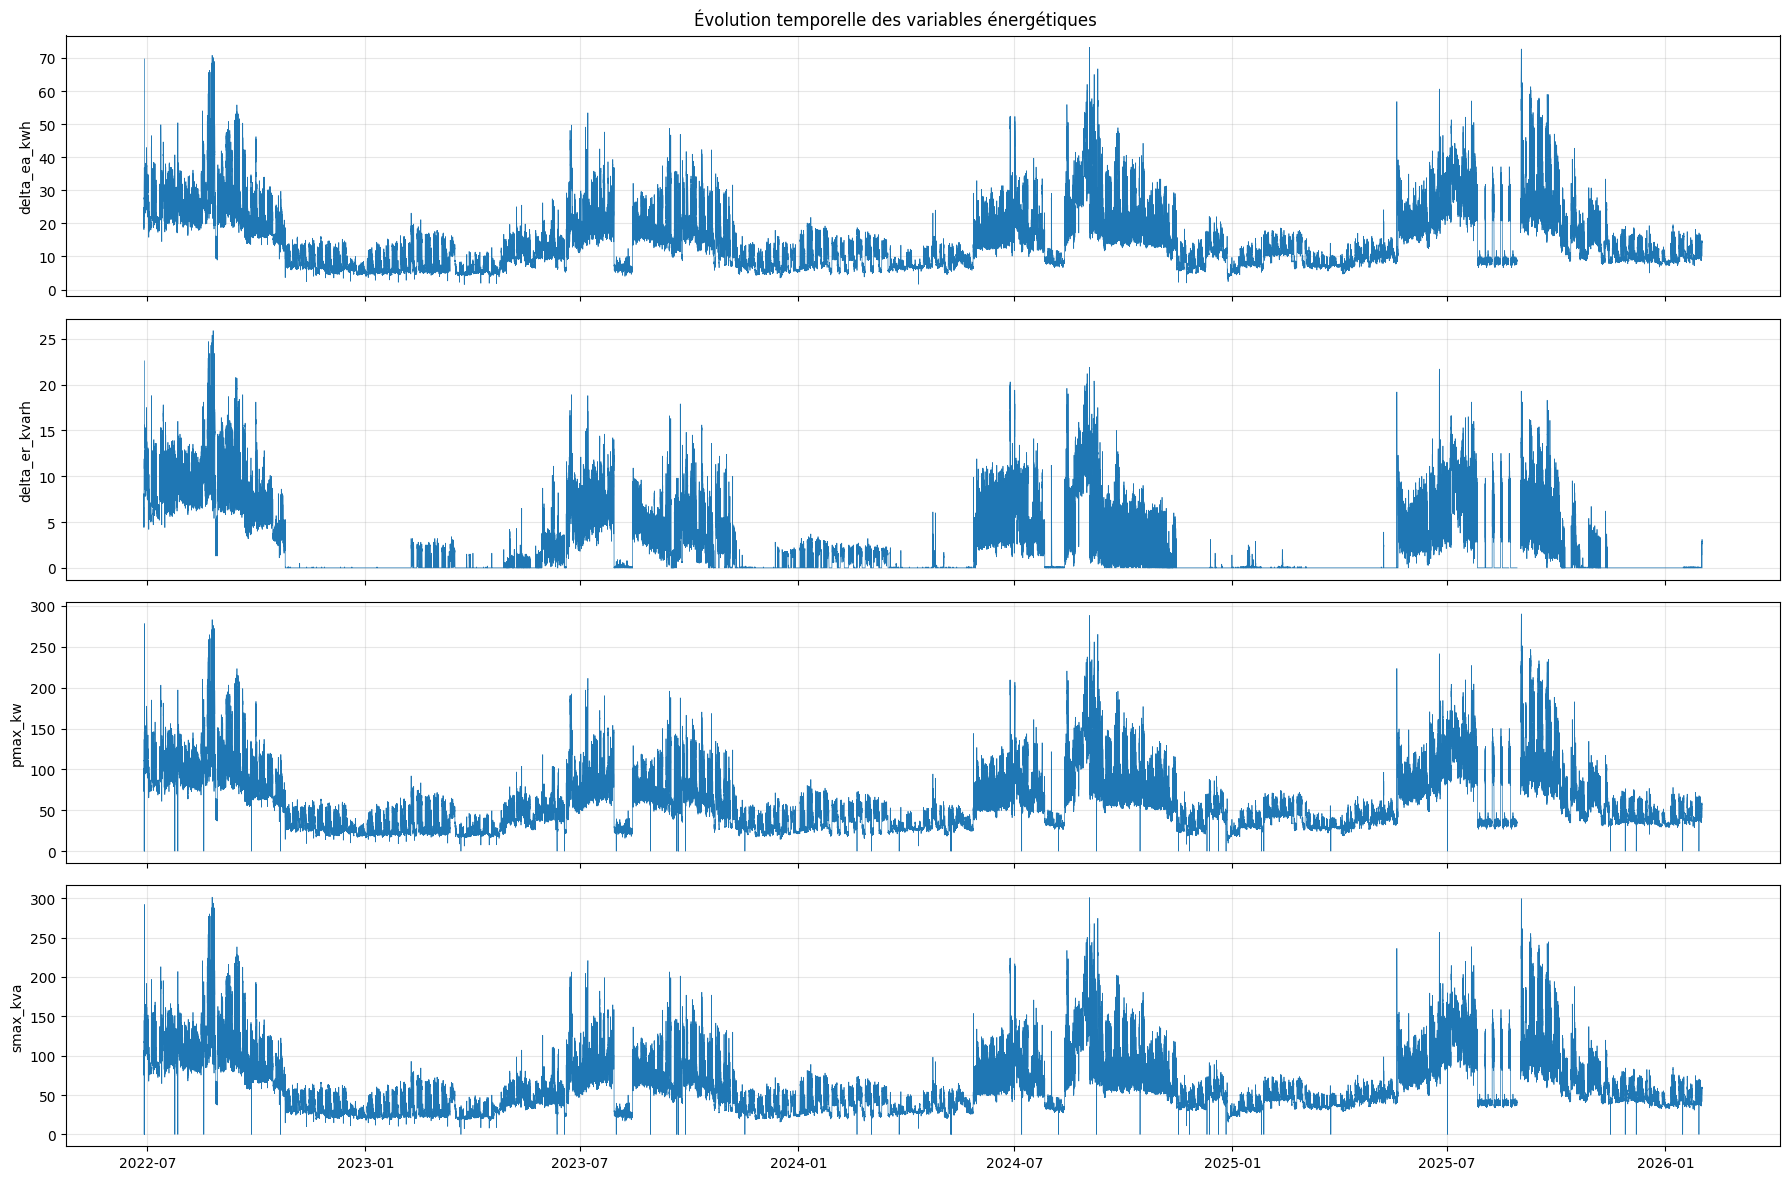

In [14]:
import matplotlib.pyplot as plt

physical_columns = [
    "delta_ea_kwh",
    "delta_er_kvarh",
    "pmax_kw",
    "smax_kva",
]

fig, axes = plt.subplots(
    4, 1,
    figsize=(18, 12),
    sharex=True
)

for ax, column in zip(axes, physical_columns):
    ax.plot(
        clean.index,
        clean[column],
        linewidth=0.5
    )
    ax.set_ylabel(column)
    ax.grid(alpha=0.3)

fig.suptitle("Évolution temporelle des variables énergétiques")
plt.tight_layout()
plt.show()

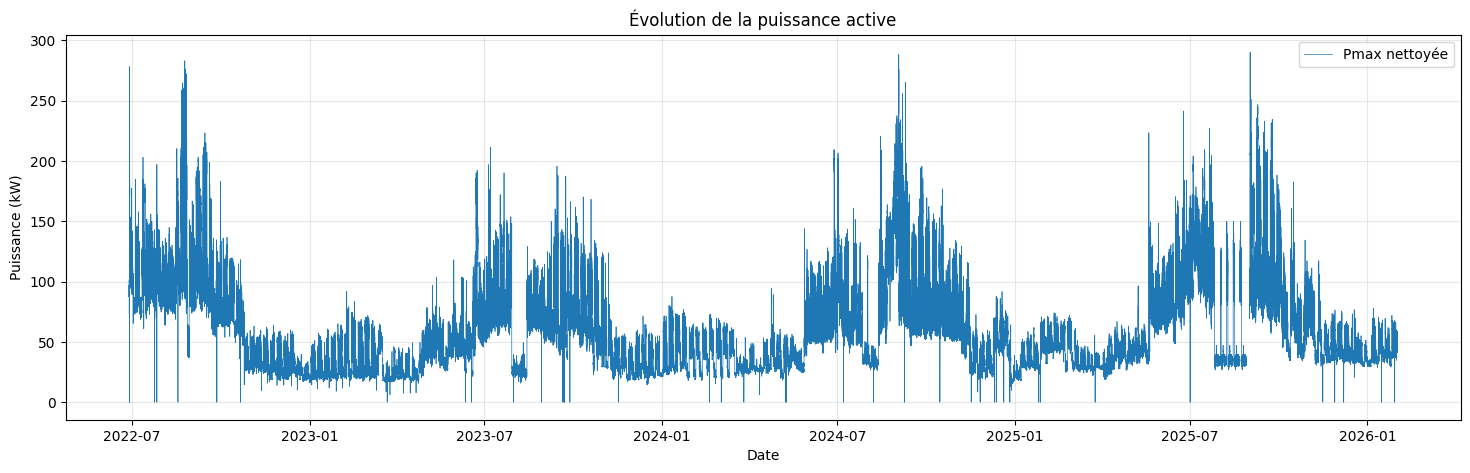

In [15]:
plt.figure(figsize=(18, 5))

plt.plot(
    clean.index,
    clean["pmax_kw"],
    linewidth=0.5,
    label="Pmax nettoyée"
)

plt.title("Évolution de la puissance active")
plt.xlabel("Date")
plt.ylabel("Puissance (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

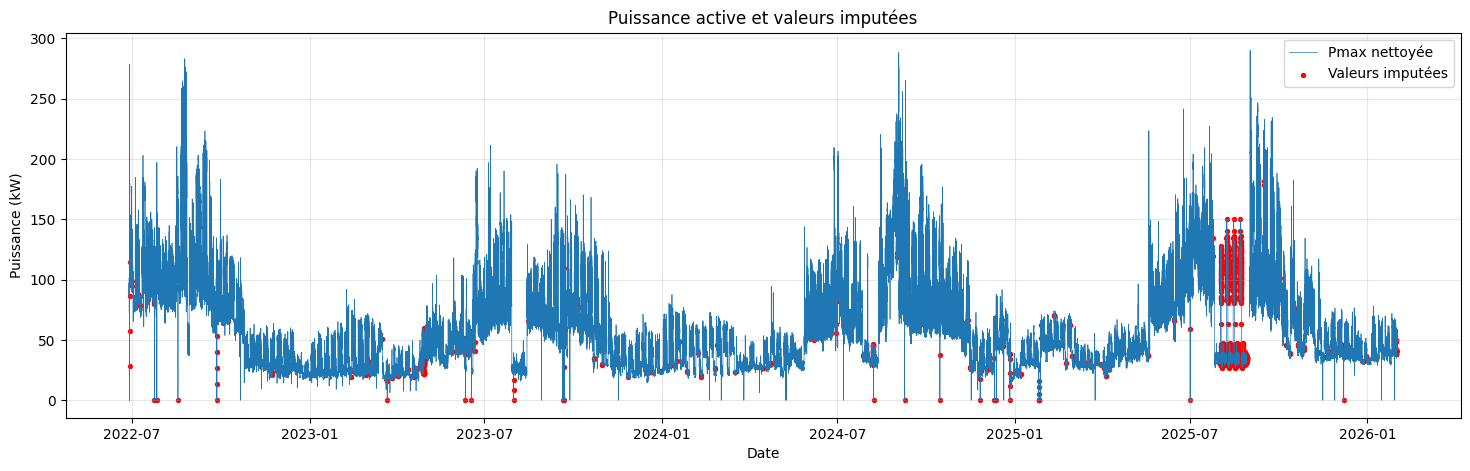

In [16]:
import matplotlib.pyplot as plt

imputed = clean["was_imputed"].fillna(False)

plt.figure(figsize=(18, 5))

plt.plot(
    clean.index,
    clean["pmax_kw"],
    linewidth=0.5,
    label="Pmax nettoyée"
)

plt.scatter(
    clean.index[imputed],
    clean.loc[imputed, "pmax_kw"],
    color="red",
    s=8,
    label="Valeurs imputées"
)

plt.title("Puissance active et valeurs imputées")
plt.xlabel("Date")
plt.ylabel("Puissance (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

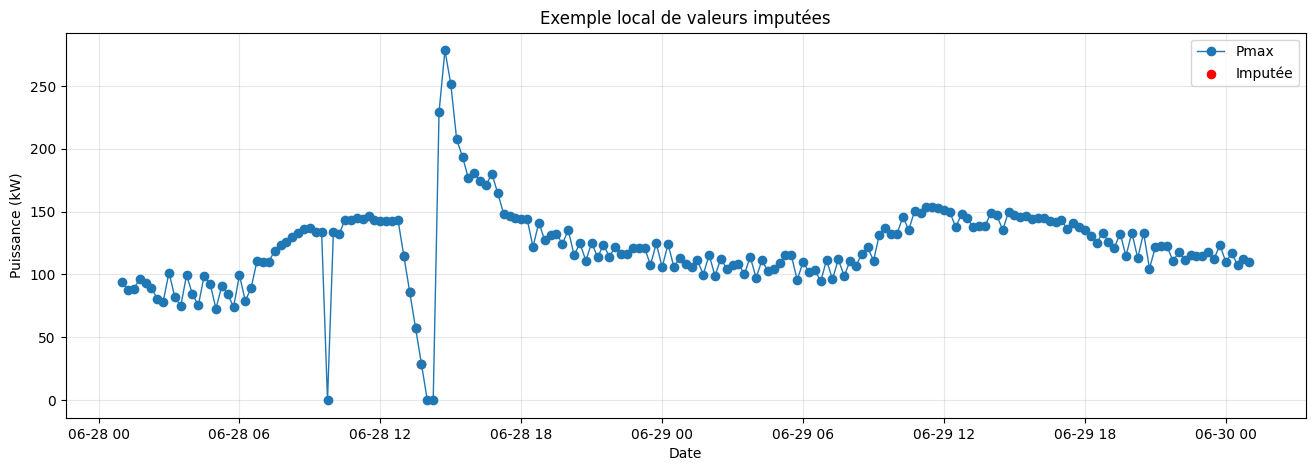

In [17]:
if imputed.any():
    first_imputed = clean.index[imputed][0]

    start = first_imputed - pd.Timedelta(hours=12)
    end = first_imputed + pd.Timedelta(hours=36)

    sample = clean.loc[start:end]
    sample_imputed = sample["was_imputed"].fillna(False)

    plt.figure(figsize=(16, 5))

    plt.plot(
        sample.index,
        sample["pmax_kw"],
        marker="o",
        linewidth=1,
        label="Pmax"
    )

    plt.scatter(
        sample.index[sample_imputed],
        sample.loc[sample_imputed, "pmax_kw"],
        color="red",
        s=35,
        label="Imputée"
    )

    plt.title("Exemple local de valeurs imputées")
    plt.xlabel("Date")
    plt.ylabel("Puissance (kW)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("Aucune valeur imputée.")

In [18]:
# Créneau horaire de 15 minutes
clean["time_slot"] = clean.index.strftime("%H:%M")

daily_profile = clean.groupby("time_slot")[
    ["delta_ea_kwh", "pmax_kw", "smax_kva"]
].mean()

display(daily_profile.head())

,delta_ea_kwh,pmax_kw,smax_kva
time_slot,,,
00:00,12.788439,52.110885,55.338501
00:15,12.617048,51.46061,54.680816
00:30,12.375362,50.442838,53.627117
00:45,12.332952,49.567887,52.726995
01:00,12.307551,49.304294,52.439504


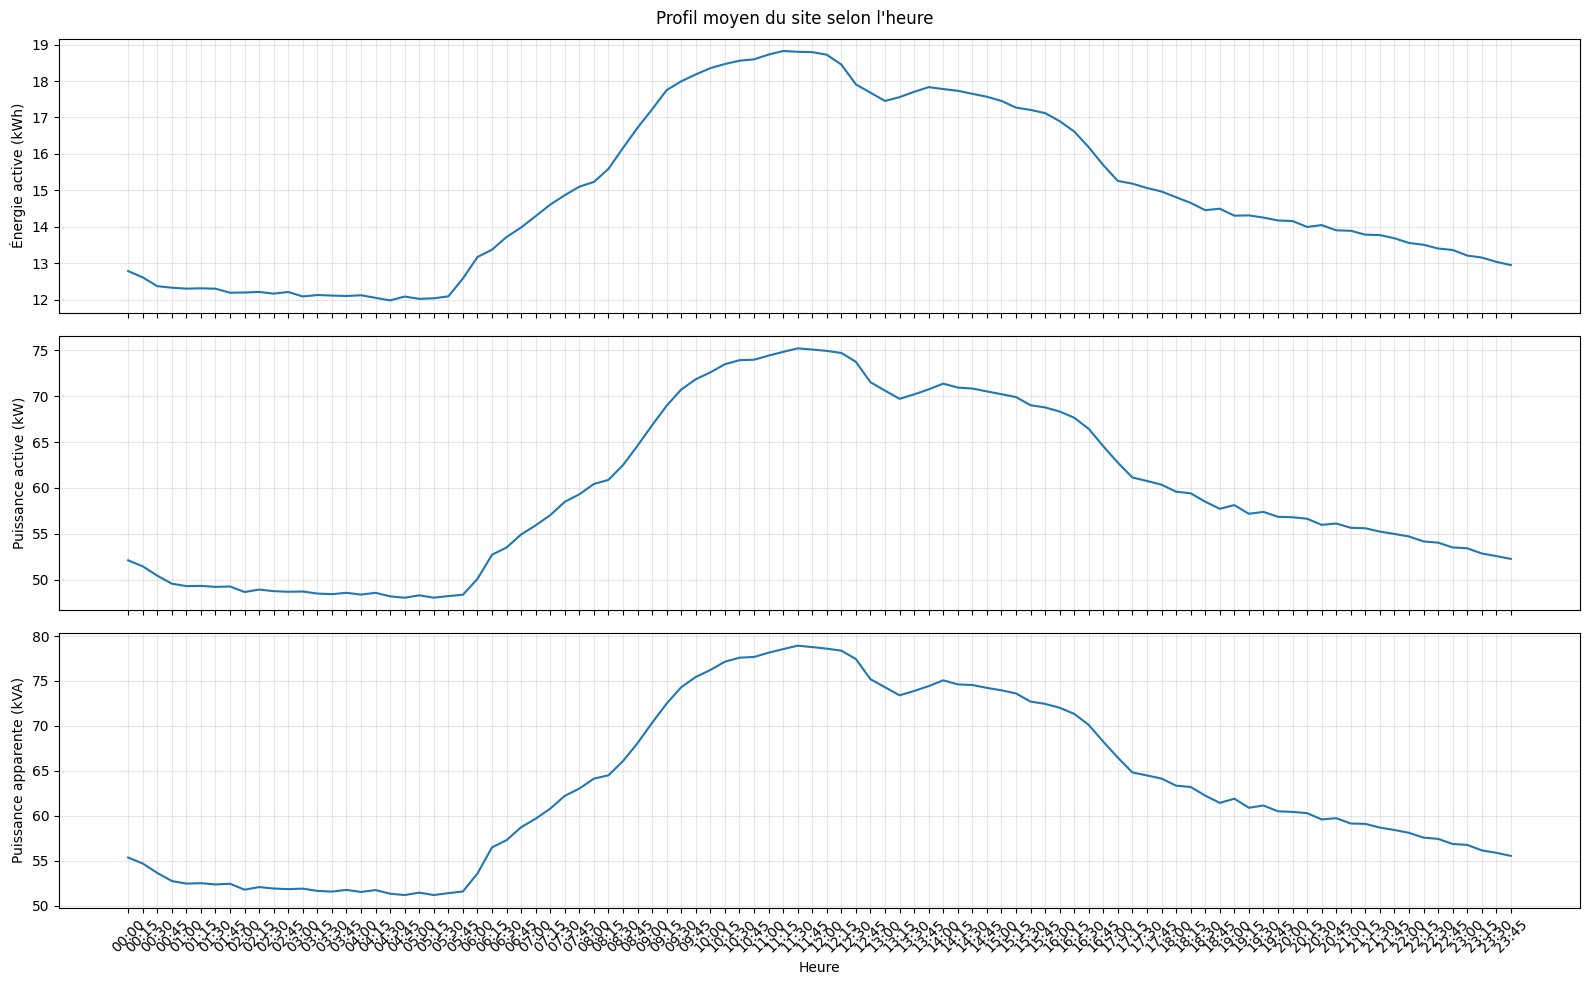

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

for ax, column, label in zip(
    axes,
    ["delta_ea_kwh", "pmax_kw", "smax_kva"],
    ["Énergie active (kWh)", "Puissance active (kW)", "Puissance apparente (kVA)"]
):
    ax.plot(daily_profile.index, daily_profile[column])
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Heure")
plt.xticks(rotation=45)
fig.suptitle("Profil moyen du site selon l'heure")
plt.tight_layout()
plt.show()

In [20]:
for column in ["delta_ea_kwh", "pmax_kw", "smax_kva"]:
    time_of_max = daily_profile[column].idxmax()
    value_of_max = daily_profile[column].max()
    print(f"{column} : {value_of_max:.2f} à {time_of_max}")

delta_ea_kwh : 18.82 à 11:15
pmax_kw : 75.21 à 11:30
smax_kva : 78.93 à 11:30


In [21]:
for column in ["delta_ea_kwh", "pmax_kw", "smax_kva"]:
    time_of_min = daily_profile[column].idxmin()
    value_of_min = daily_profile[column].min()
    print(f"{column} : {value_of_min:.2f} à {time_of_min}")

delta_ea_kwh : 11.99 à 04:30
pmax_kw : 48.04 à 04:45
smax_kva : 51.16 à 05:15


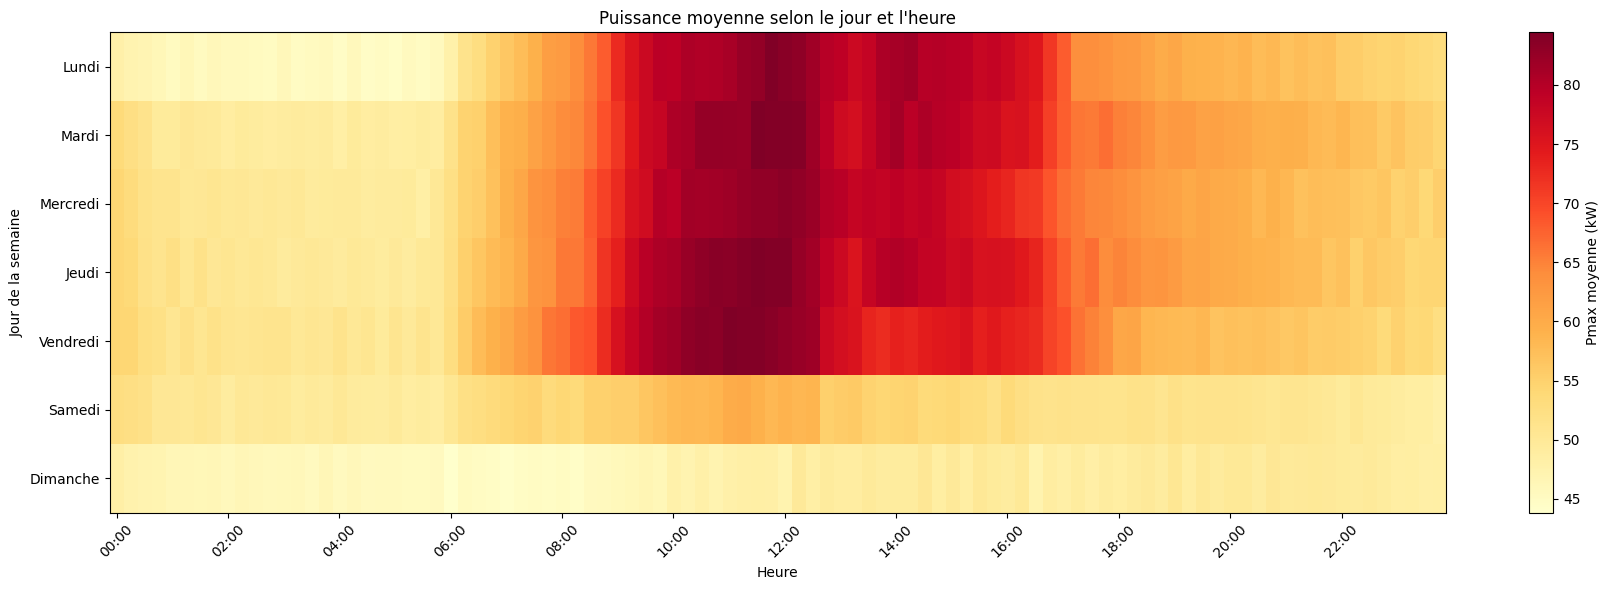

In [23]:
import matplotlib.pyplot as plt
import numpy as np

clean["weekday_number"] = clean.index.dayofweek

# Conversion numérique des valeurs
clean["pmax_kw_numeric"] = pd.to_numeric(
    clean["pmax_kw"],
    errors="coerce"
)

heatmap_data = clean.pivot_table(
    index="weekday_number",
    columns="time_slot",
    values="pmax_kw_numeric",
    aggfunc="mean"
)

# Conversion obligatoire pour imshow
heatmap_values = heatmap_data.to_numpy(dtype=float)

weekday_labels = [
    "Lundi", "Mardi", "Mercredi",
    "Jeudi", "Vendredi", "Samedi", "Dimanche"
]

fig, ax = plt.subplots(figsize=(18, 6))

image = ax.imshow(
    heatmap_values,
    aspect="auto",
    cmap="YlOrRd"
)

ax.set_yticks(range(7))
ax.set_yticklabels(weekday_labels)

step = max(1, len(heatmap_data.columns) // 12)

ax.set_xticks(range(0, len(heatmap_data.columns), step))
ax.set_xticklabels(
    heatmap_data.columns[::step],
    rotation=45
)

ax.set_title("Puissance moyenne selon le jour et l'heure")
ax.set_xlabel("Heure")
ax.set_ylabel("Jour de la semaine")

fig.colorbar(
    image,
    ax=ax,
    label="Pmax moyenne (kW)"
)

plt.tight_layout()
plt.show()

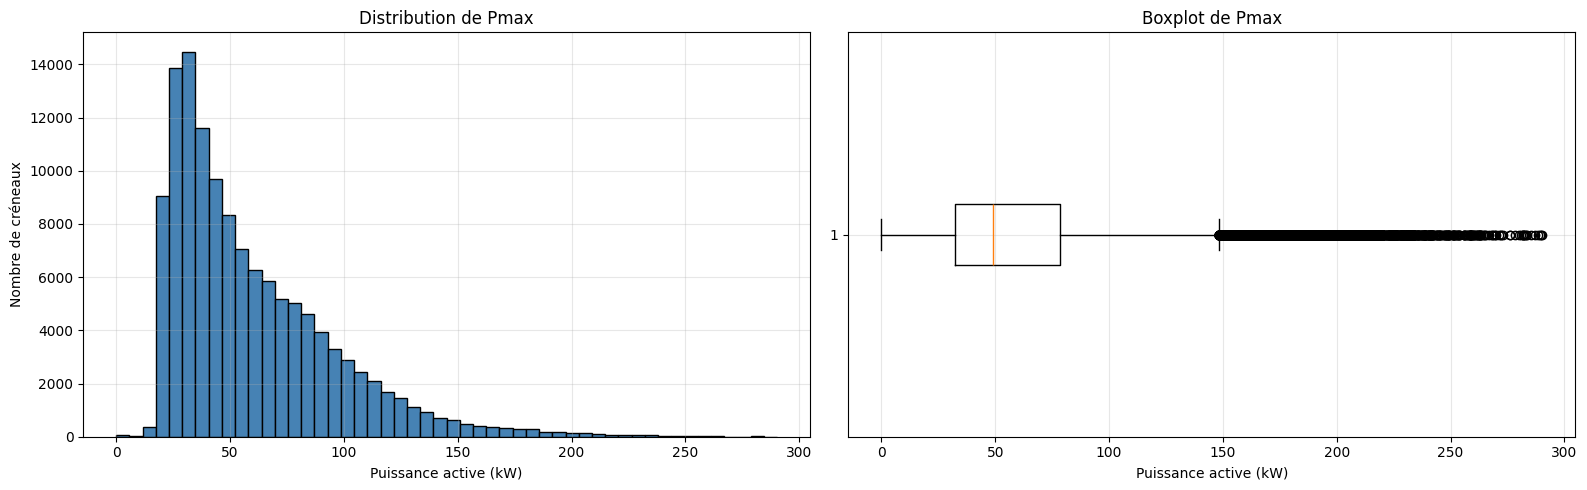

In [24]:
import matplotlib.pyplot as plt
import numpy as np

pmax_values = pd.to_numeric(
    clean["pmax_kw"],
    errors="coerce"
).dropna()

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5)
)

# Histogramme
axes[0].hist(
    pmax_values,
    bins=50,
    color="steelblue",
    edgecolor="black"
)

axes[0].set_title("Distribution de Pmax")
axes[0].set_xlabel("Puissance active (kW)")
axes[0].set_ylabel("Nombre de créneaux")
axes[0].grid(alpha=0.3)

# Boxplot
axes[1].boxplot(
    pmax_values,
    vert=False
)

axes[1].set_title("Boxplot de Pmax")
axes[1].set_xlabel("Puissance active (kW)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
print("Statistiques de Pmax :")
display(pmax_values.describe())

Statistiques de Pmax :


count     125856.0
mean     59.659404
std      36.263444
min            0.0
25%          32.19
50%          48.95
75%        78.5525
max         290.25
Name: pmax_kw, dtype: Float64

In [26]:
percentiles = pmax_values.quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(percentiles)

0.01       18.42
0.05       21.33
0.25       32.19
0.50       48.95
0.75     78.5525
0.90      108.51
0.95      129.49
0.99    183.5845
Name: pmax_kw, dtype: Float64

In [27]:
clean["delta_ea_numeric"] = pd.to_numeric(
    clean["delta_ea_kwh"],
    errors="coerce"
)

daily_energy = clean["delta_ea_numeric"].resample("D").sum(min_count=1)
weekly_energy = clean["delta_ea_numeric"].resample("W").sum(min_count=1)
monthly_energy = clean["delta_ea_numeric"].resample("MS").sum(min_count=1)
annual_energy = clean["delta_ea_numeric"].resample("YS").sum(min_count=1)

print("Énergie journalière :")
display(daily_energy.head())

print("Énergie hebdomadaire :")
display(weekly_energy.head())

print("Énergie mensuelle :")
display(monthly_energy)

print("Énergie annuelle :")
display(annual_energy)

Énergie journalière :


timestamp
2022-06-01    <NA>
2022-06-02    <NA>
2022-06-03    <NA>
2022-06-04    <NA>
2022-06-05    <NA>
Freq: D, Name: delta_ea_numeric, dtype: Float64

Énergie hebdomadaire :


timestamp
2022-06-05       <NA>
2022-06-12       <NA>
2022-06-19       <NA>
2022-06-26       <NA>
2022-07-03    15191.7
Freq: W-SUN, Name: delta_ea_numeric, dtype: Float64

Énergie mensuelle :


timestamp
2022-06-01     8772.7
2022-07-01    75705.6
2022-08-01    84301.5
2022-09-01    79391.1
2022-10-01    51193.3
2022-11-01    26116.7
2022-12-01    21688.4
2023-01-01    22379.7
2023-02-01    24602.3
2023-03-01    23113.1
2023-04-01    18791.4
2023-05-01    34834.7
2023-06-01    44163.1
2023-07-01    63261.0
2023-08-01    42549.3
2023-09-01    57588.7
2023-10-01    52982.6
2023-11-01    27009.8
2023-12-01    23376.1
2024-01-01    30288.8
2024-02-01    27969.9
2024-03-01    25194.4
2024-04-01    24093.8
2024-05-01    28556.3
2024-06-01    55038.8
2024-07-01    55425.2
2024-08-01    65308.4
2024-09-01    75161.2
2024-10-01    62802.7
2024-11-01    35931.3
2024-12-01    31904.0
2025-01-01    26513.1
2025-02-01    33366.1
2025-03-01    23839.3
2025-04-01    27221.7
2025-05-01    43601.7
2025-06-01    69376.2
2025-07-01    81220.9
2025-08-01    31766.5
2025-09-01    88449.7
2025-10-01    51024.2
2025-11-01    37517.4
2025-12-01    32063.1
2026-01-01    32475.8
2026-02-01       10.2


Énergie annuelle :


timestamp
2022-01-01    347169.3
2023-01-01    434651.8
2024-01-01    517674.8
2025-01-01    545959.9
2026-01-01     32486.0
Freq: YS-JAN, Name: delta_ea_numeric, dtype: Float64

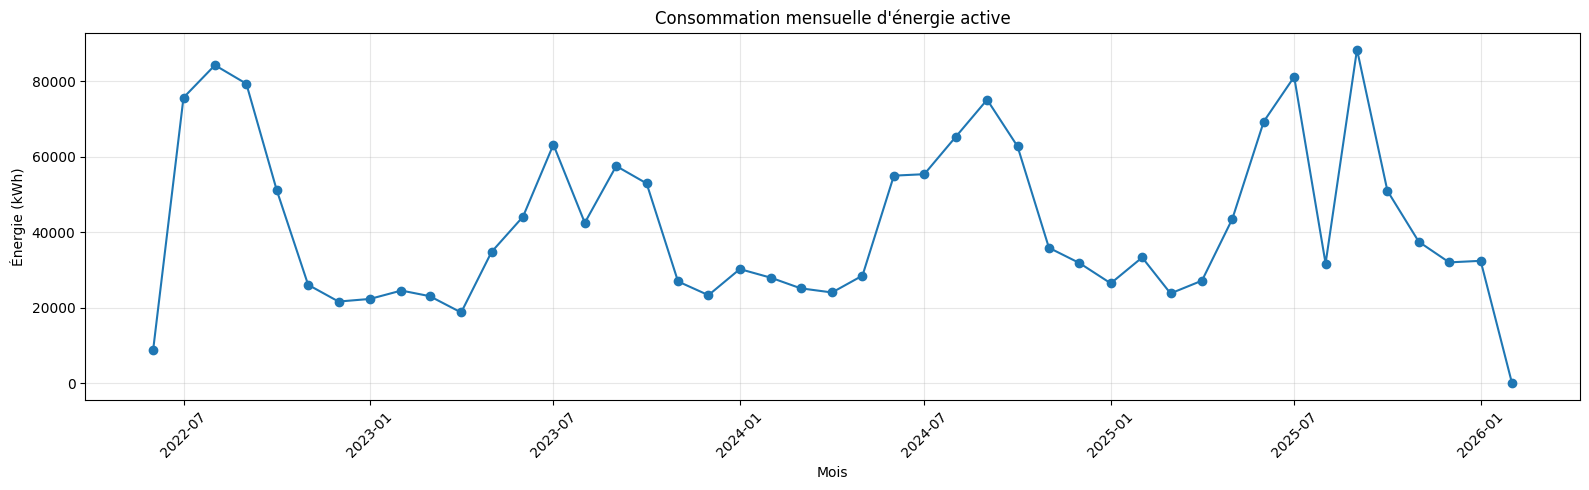

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 5))

plt.plot(
    monthly_energy.index,
    monthly_energy.values,
    marker="o"
)

plt.title("Consommation mensuelle d'énergie active")
plt.xlabel("Mois")
plt.ylabel("Énergie (kWh)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
month_max = monthly_energy.idxmax()
month_min = monthly_energy.idxmin()

print(
    "Mois le plus consommateur :",
    month_max.strftime("%Y-%m"),
    "avec",
    round(monthly_energy.max(), 2),
    "kWh"
)

print(
    "Mois le moins consommateur :",
    month_min.strftime("%Y-%m"),
    "avec",
    round(monthly_energy.min(), 2),
    "kWh"
)

Mois le plus consommateur : 2025-09 avec 88449.7 kWh
Mois le moins consommateur : 2026-02 avec 10.2 kWh


In [30]:
expected_per_day = 96

coverage_daily = clean["delta_ea_numeric"].resample("D").agg(
    valid_intervals="count",
    total_intervals="size"
)

coverage_daily["coverage_percent"] = (
    coverage_daily["valid_intervals"]
    / expected_per_day
    * 100
)

display(coverage_daily.head())

,valid_intervals,total_intervals,coverage_percent
timestamp,,,
2022-06-01,0,96,0.0
2022-06-02,0,96,0.0
2022-06-03,0,96,0.0
2022-06-04,0,96,0.0
2022-06-05,0,96,0.0


In [31]:
coverage_monthly = clean["delta_ea_numeric"].resample("MS").agg(
    valid_intervals="count",
    total_intervals="size"
)

coverage_monthly["coverage_percent"] = (
    coverage_monthly["valid_intervals"]
    / coverage_monthly["total_intervals"]
    * 100
)

display(coverage_monthly)

,valid_intervals,total_intervals,coverage_percent
timestamp,,,
2022-06-01,282,2880,9.791667
2022-07-01,2976,2976,100.0
2022-08-01,2976,2976,100.0
2022-09-01,2880,2880,100.0
2022-10-01,2976,2976,100.0
2022-11-01,2880,2880,100.0
2022-12-01,2976,2976,100.0
2023-01-01,2976,2976,100.0
2023-02-01,2688,2688,100.0


In [32]:
pmax_values = pd.to_numeric(
    clean["pmax_kw"],
    errors="coerce"
).dropna()

base_absolute = pmax_values.min()
base_q05 = pmax_values.quantile(0.05)
base_median = pmax_values.median()

print(f"Minimum absolu : {base_absolute:.2f} kW")
print(f"Charge de base robuste (5e percentile) : {base_q05:.2f} kW")
print(f"Médiane : {base_median:.2f} kW")

Minimum absolu : 0.00 kW
Charge de base robuste (5e percentile) : 21.33 kW
Médiane : 48.95 kW


In [33]:
pmax_value = pmax_values.max()
pmax_time = pmax_values.idxmax()

smax_values = pd.to_numeric(
    clean["smax_kva"],
    errors="coerce"
).dropna()

smax_value = smax_values.max()
smax_time = smax_values.idxmax()

print(f"Pmax maximale : {pmax_value:.2f} kW à {pmax_time}")
print(f"Smax maximale : {smax_value:.2f} kVA à {smax_time}")

Pmax maximale : 290.25 kW à 2025-09-01 14:30:00
Smax maximale : 301.17 kVA à 2022-08-24 17:15:00


In [34]:
top_pmax = pmax_values.nlargest(10)

top_peaks = pd.DataFrame({
    "timestamp": top_pmax.index,
    "pmax_kw": top_pmax.values,
    "heure": top_pmax.index.strftime("%H:%M"),
    "jour": top_pmax.index.strftime("%A"),
})

display(top_peaks)

,timestamp,pmax_kw,heure,jour
0,2025-09-01 14:30:00,290.25,14:30,Monday
1,2025-09-01 14:00:00,289.53,14:00,Monday
2,2025-09-01 14:15:00,289.38,14:15,Monday
3,2024-09-02 11:30:00,288.36,11:30,Monday
4,2024-09-02 11:15:00,287.18,11:15,Monday
5,2025-09-01 13:30:00,285.12,13:30,Monday
6,2024-09-02 12:00:00,283.55,12:00,Monday
7,2022-08-24 17:15:00,283.23,17:15,Wednesday
8,2024-09-02 10:15:00,282.65,10:15,Monday
9,2024-09-02 10:30:00,282.33,10:30,Monday


In [35]:
peak_threshold = pmax_values.quantile(0.90)

clean["is_peak"] = (
    pd.to_numeric(clean["pmax_kw"], errors="coerce")
    >= peak_threshold
)

print(f"Seuil de pic : {peak_threshold:.2f} kW")
print("Nombre de créneaux de pic :", clean["is_peak"].sum())
print(
    "Durée totale des pics :",
    clean["is_peak"].sum() * 15 / 60,
    "heures"
)

Seuil de pic : 108.51 kW
Nombre de créneaux de pic : 12589
Durée totale des pics : 3147.25 heures


In [37]:
pmax_values = pd.to_numeric(
    clean["pmax_kw"],
    errors="coerce"
)

peak_threshold = pmax_values.quantile(0.90)

clean["is_peak"] = (
    pmax_values >= peak_threshold
).fillna(False)

print(f"Seuil de pic : {peak_threshold:.2f} kW")
print("Nombre de créneaux de pic :", int(clean["is_peak"].sum()))
print(
    "Durée totale des pics :",
    round(clean["is_peak"].sum() * 15 / 60, 2),
    "heures"
)

Seuil de pic : 108.51 kW
Nombre de créneaux de pic : 12589
Durée totale des pics : 3147.25 heures


In [38]:
peak_group_id = (
    clean["is_peak"]
    .ne(clean["is_peak"].shift())
    .cumsum()
)

peak_episodes = (
    clean[clean["is_peak"]]
    .groupby(peak_group_id)
    .agg(
        debut=("pmax_kw", lambda values: values.index.min()),
        fin=("pmax_kw", lambda values: values.index.max()),
        pmax=("pmax_kw", "max"),
        nombre_creneaux=("pmax_kw", "size")
    )
)

peak_episodes["duree_heures"] = (
    peak_episodes["nombre_creneaux"] * 15 / 60
)

peak_episodes = peak_episodes.sort_values(
    "pmax",
    ascending=False
)

display(peak_episodes.head(10))

,debut,fin,pmax,nombre_creneaux,duree_heures
is_peak,,,,,
4615,2025-09-01 07:15:00,2025-09-01 18:45:00,290.25,47,11.75
2751,2024-08-31 05:00:00,2024-09-02 17:00:00,288.36,241,60.25
999,2022-08-24 06:30:00,2022-08-24 22:30:00,283.23,65,16.25
5,2022-06-28 14:30:00,2022-06-28 23:15:00,278.38,36,9.0
1013,2022-08-25 08:00:00,2022-08-25 23:15:00,276.17,62,15.5
1019,2022-08-26 08:30:00,2022-08-27 03:00:00,272.31,75,18.75
2835,2024-09-09 09:00:00,2024-09-09 17:30:00,265.25,35,8.75
983,2022-08-22 07:45:00,2022-08-23 03:30:00,264.78,80,20.0
993,2022-08-23 07:00:00,2022-08-24 01:45:00,260.12,76,19.0


In [39]:
longest_episodes = peak_episodes.sort_values(
    "duree_heures",
    ascending=False
)

display(longest_episodes.head(10))

,debut,fin,pmax,nombre_creneaux,duree_heures
is_peak,,,,,
3909,2025-07-04 07:45:00,2025-07-09 17:00:00,204.19,518,129.5
2749,2024-08-28 07:30:00,2024-08-31 04:30:00,230.99,277,69.25
2751,2024-08-31 05:00:00,2024-09-02 17:00:00,288.36,241,60.25
957,2022-08-20 12:15:00,2022-08-21 18:45:00,258.88,123,30.75
1683,2023-06-23 09:15:00,2023-06-24 11:15:00,192.38,105,26.25
2671,2024-08-23 07:15:00,2024-08-24 06:15:00,154.23,93,23.25
2683,2024-08-25 08:30:00,2024-08-26 06:00:00,146.97,87,21.75
983,2022-08-22 07:45:00,2022-08-23 03:30:00,264.78,80,20.0
993,2022-08-23 07:00:00,2022-08-24 01:45:00,260.12,76,19.0


In [40]:
print("Nombre total d'épisodes :", len(peak_episodes))
print(
    "Durée moyenne :",
    round(peak_episodes["duree_heures"].mean(), 2),
    "heures"
)
print(
    "Durée maximale :",
    round(peak_episodes["duree_heures"].max(), 2),
    "heures"
)
print(
    "Pmax moyenne pendant les épisodes :",
    round(peak_episodes["pmax"].mean(), 2),
    "kW"
)

Nombre total d'épisodes : 2646
Durée moyenne : 1.19 heures
Durée maximale : 129.5 heures
Pmax moyenne pendant les épisodes : 123.65 kW


In [41]:
peak_rows = clean[clean["is_peak"]].copy()

peak_rows["heure"] = peak_rows.index.strftime("%H:%M")

peak_hours = (
    peak_rows["heure"]
    .value_counts()
    .sort_index()
)

display(peak_hours.sort_values(ascending=False).head(10))

heure
11:30    288
11:15    277
12:30    274
11:45    272
11:00    271
12:15    270
12:00    268
10:45    266
10:15    259
14:00    257
Name: count, dtype: int64

In [42]:
import numpy as np

clean["period_type"] = np.where(
    clean["is_nonworking_day"] == 1,
    "Non ouvré",
    "Ouvré"
)

print(clean["period_type"].value_counts())

period_type
Ouvré        91968
Non ouvré    36769
Name: count, dtype: int64


In [43]:
comparison = clean.groupby("period_type")[
    ["delta_ea_kwh", "pmax_kw", "smax_kva"]
].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

display(comparison)

delta_ea_kwh                                        pmax_kw  \
                   count       mean median       std  min   max   count   
period_type                                                               
Non ouvré          35809  12.517384    9.5  7.618265  1.5  65.6   35809   
Ouvré              90039   15.87875   13.1  9.405775  1.6  73.2   90047   

                                                      smax_kva             \
                  mean median        std  min     max    count       mean   
period_type                                                                 
Non ouvré    50.068736  37.79  30.497072  0.0  258.88    35809  53.489106   
Ouvré        63.473326  52.39  37.643249  0.0  290.25    90047  67.020006   

                                            
            median        std  min     max  
period_type                                 
Non ouvré    42.31  31.352515  0.0  276.87  
Ouvré        55.63  38.751958  0.0  301.17

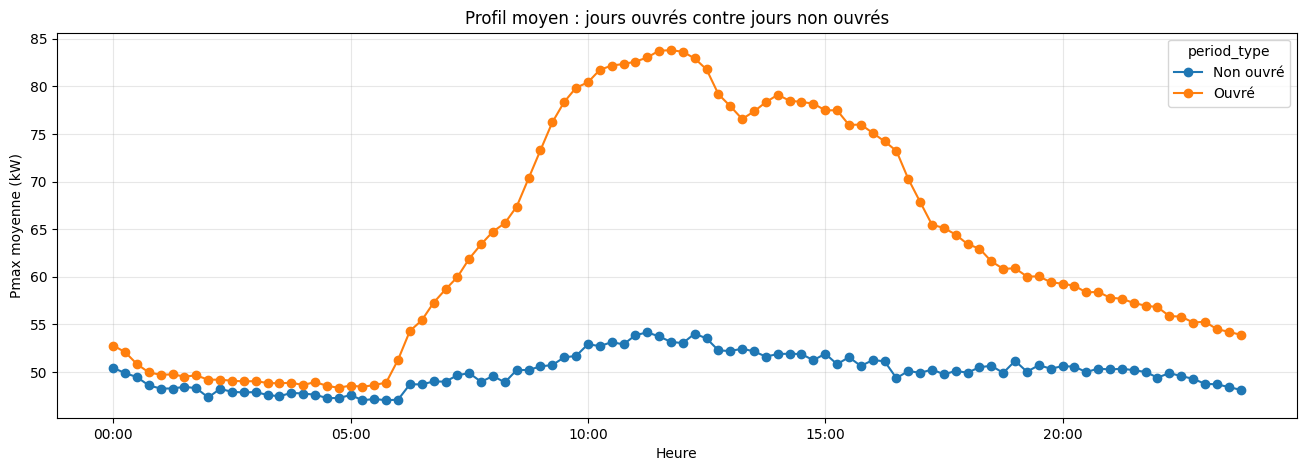

In [44]:
hourly_comparison = clean.groupby(
    ["period_type", "time_slot"]
)["pmax_kw"].mean().unstack(0)

hourly_comparison.plot(
    figsize=(16, 5),
    marker="o"
)

plt.title("Profil moyen : jours ouvrés contre jours non ouvrés")
plt.xlabel("Heure")
plt.ylabel("Pmax moyenne (kW)")
plt.grid(alpha=0.3)
plt.show()

In [45]:
daily_period = clean.groupby(
    [clean.index.normalize(), "period_type"]
)["delta_ea_kwh"].sum(min_count=1)

daily_period = daily_period.reset_index()
daily_period.columns = ["date", "period_type", "energy_kwh"]

display(daily_period.groupby("period_type")["energy_kwh"].describe())

,count,mean,std,min,25%,50%,75%,max
period_type,,,,,,,,
Non ouvré,374.0,1198.489305,693.697441,10.2,657.35,911.8,1705.925,4100.3
Ouvré,938.0,1524.207676,791.917772,438.2,901.7,1202.15,2077.025,4339.8


In [46]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Hiver"
    if month in [3, 4, 5]:
        return "Printemps"
    if month in [6, 7, 8]:
        return "Été"
    return "Automne"

clean["season"] = clean.index.month.map(get_season)

season_summary = clean.groupby("season")[
    ["delta_ea_kwh", "pmax_kw", "smax_kva"]
].agg([
    "count",
    "mean",
    "median",
    "std",
    "sum",
    "max"
])

display(season_summary)

delta_ea_kwh                                             pmax_kw  \
                 count       mean median       std       sum   max   count   
season                                                                       
Automne          34943   18.46346   17.0  9.595366  645168.7  73.2   34944   
Hiver            31969   9.591714    9.1  3.513061  306637.5  23.1   31969   
Printemps        26496   9.406944    8.4  3.935915  249246.4  56.8   26496   
Été              32440  20.865882   20.5  9.636821  676889.2  70.8   32447   

                                                            smax_kva  \
                mean median        std          sum     max    count   
season                                                                 
Automne    73.828445  67.81  38.408924  2579861.185  290.25    34944   
Hiver      38.330019  36.18  14.072812  1225372.365    92.0    31969   
Printemps  37.621104  33.68  15.769924    996808.76  223.48    26496   
Été        83.411459  82.05  38.583075  2706451.605  283.23    32447   

                                                              
                mean  median        std          sum     max  
season                                                        
Automne    77.243765  70.025  39.157723   2699206.13  300.65  
Hiver       40.93971   39.01  14.291901  1308801.585   94.28  
Printemps  41.401091  38.665  15.834218  1096963.295  236.17  
Été         87.69288    85.9  40.633954   2845370.87  301.17

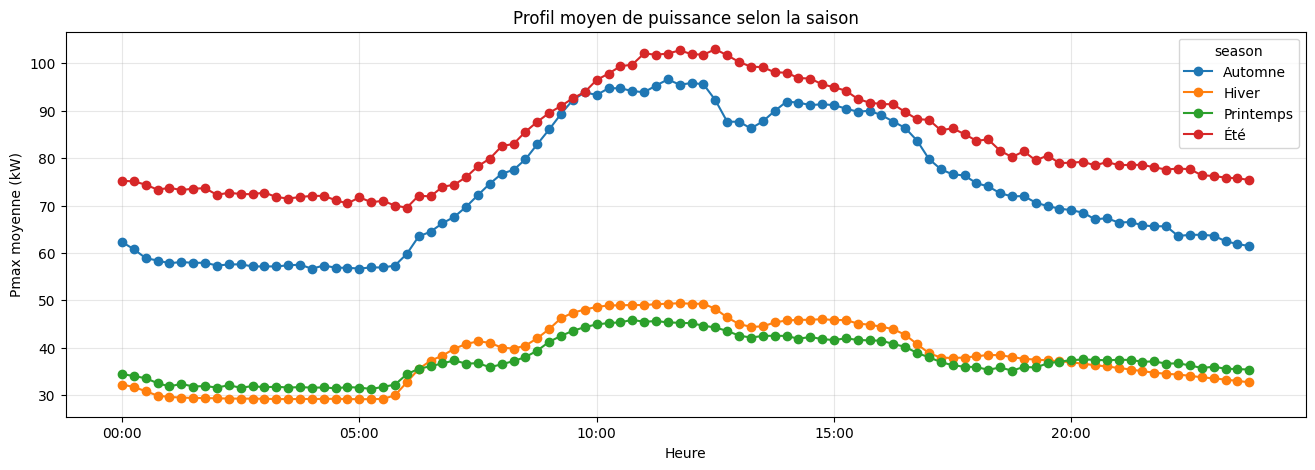

In [47]:
season_profile = clean.groupby(
    ["season", "time_slot"]
)["pmax_kw"].mean().unstack(0)

season_profile.plot(
    figsize=(16, 5),
    marker="o"
)

plt.title("Profil moyen de puissance selon la saison")
plt.xlabel("Heure")
plt.ylabel("Pmax moyenne (kW)")
plt.grid(alpha=0.3)
plt.show()

In [48]:
season_energy = clean.groupby("season")["delta_ea_kwh"].sum()

display(season_energy.sort_values(ascending=False))

season
Été          676889.2
Automne      645168.7
Hiver        306637.5
Printemps    249246.4
Name: delta_ea_kwh, dtype: Float64

In [49]:
season_mean = clean.groupby("season")[
    ["delta_ea_kwh", "pmax_kw", "smax_kva"]
].mean()

display(season_mean)

,delta_ea_kwh,pmax_kw,smax_kva
season,,,
Automne,18.46346,73.828445,77.243765
Hiver,9.591714,38.330019,40.93971
Printemps,9.406944,37.621104,41.401091
Été,20.865882,83.411459,87.69288


In [50]:
activation_threshold = 1.0

clean["pmax_numeric"] = pd.to_numeric(
    clean["pmax_kw"],
    errors="coerce"
)

clean["is_active"] = (
    clean["pmax_numeric"] >= activation_threshold
).fillna(False)

print("Créneaux actifs :", int(clean["is_active"].sum()))
print("Créneaux inactifs :", int((~clean["is_active"]).sum()))

Créneaux actifs : 125795
Créneaux inactifs : 2942


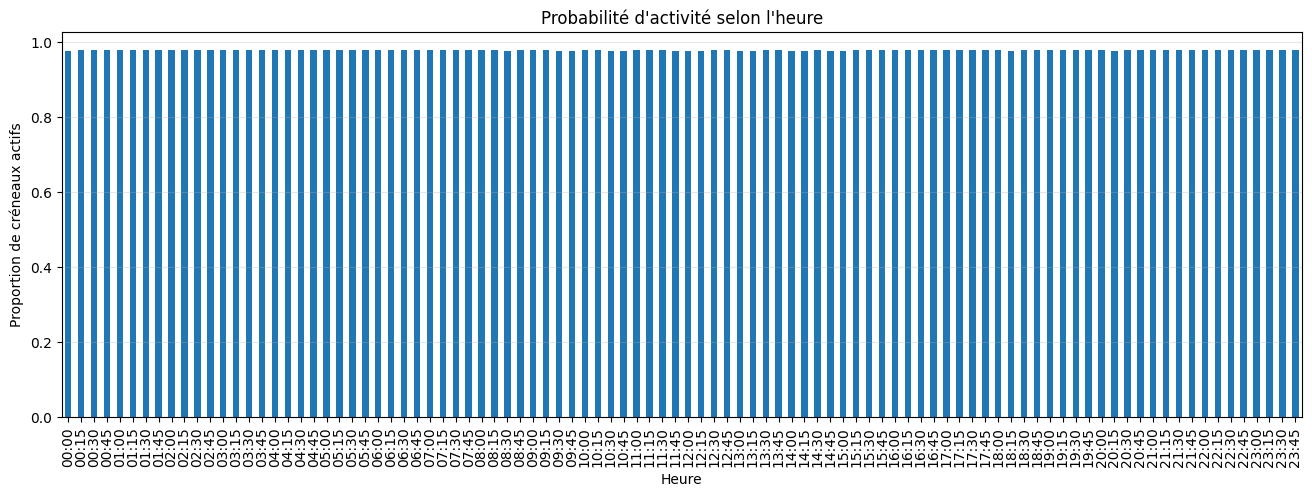

In [51]:
activation_by_hour = (
    clean.groupby("time_slot")["is_active"]
    .mean()
)

activation_by_hour.plot(
    kind="bar",
    figsize=(16, 5)
)

plt.title("Probabilité d'activité selon l'heure")
plt.xlabel("Heure")
plt.ylabel("Proportion de créneaux actifs")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [52]:
active_data = clean[clean["is_active"]].copy()

daily_activity = active_data.groupby(
    active_data.index.date
).agg(
    heure_activation=("pmax_numeric", lambda x: x.index.min()),
    heure_desactivation=("pmax_numeric", lambda x: x.index.max()),
    nombre_creneaux_actifs=("pmax_numeric", "size"),
    puissance_moyenne=("pmax_numeric", "mean")
)

daily_activity["duree_active_heures"] = (
    daily_activity["nombre_creneaux_actifs"] * 15 / 60
)

daily_activity["heure_activation"] = (
    daily_activity["heure_activation"].dt.strftime("%H:%M")
)

daily_activity["heure_desactivation"] = (
    daily_activity["heure_desactivation"].dt.strftime("%H:%M")
)

display(daily_activity.head())

,heure_activation,heure_desactivation,nombre_creneaux_actifs,puissance_moyenne,duree_active_heures
2022-06-28,00:00,23:45,93,123.594301,23.25
2022-06-29,00:00,23:45,96,124.046771,24.0
2022-06-30,00:00,23:45,96,123.407083,24.0
2022-07-01,00:00,23:45,96,106.55526,24.0
2022-07-02,00:00,23:45,96,82.173958,24.0


In [53]:
print("Heures d'activation les plus fréquentes :")
display(
    daily_activity["heure_activation"]
    .value_counts()
    .head(10)
)

print("Heures de désactivation les plus fréquentes :")
display(
    daily_activity["heure_desactivation"]
    .value_counts()
    .head(10)
)

Heures d'activation les plus fréquentes :


heure_activation
00:00    1310
00:15       2
Name: count, dtype: int64

Heures de désactivation les plus fréquentes :


heure_desactivation
23:45    1311
00:00       1
Name: count, dtype: int64

In [54]:
print(
    "Durée active moyenne :",
    round(daily_activity["duree_active_heures"].mean(), 2),
    "heures par jour"
)

Durée active moyenne : 23.97 heures par jour


In [55]:
for threshold in [1, 10, 30, 50, 70]:
    active_ratio = (
        clean["pmax_numeric"] >= threshold
    ).mean() * 100

    print(
        f"Seuil {threshold} kW : "
        f"{active_ratio:.2f}% des créneaux actifs"
    )

Seuil 1 kW : 99.95% des créneaux actifs
Seuil 10 kW : 99.94% des créneaux actifs
Seuil 30 kW : 79.38% des créneaux actifs
Seuil 50 kW : 48.81% des créneaux actifs
Seuil 70 kW : 30.96% des créneaux actifs


In [56]:
thresholds = [1, 10, 30, 50, 70]

activity_by_threshold = pd.DataFrame({
    f"{threshold} kW": (
        clean["pmax_numeric"] >= threshold
    ).groupby(clean["time_slot"]).mean() * 100
})

display(activity_by_threshold.head())

,70 kW
time_slot,
00:00,26.392067
00:15,26.239512
00:30,24.180015
00:45,25.019069
01:00,24.02746


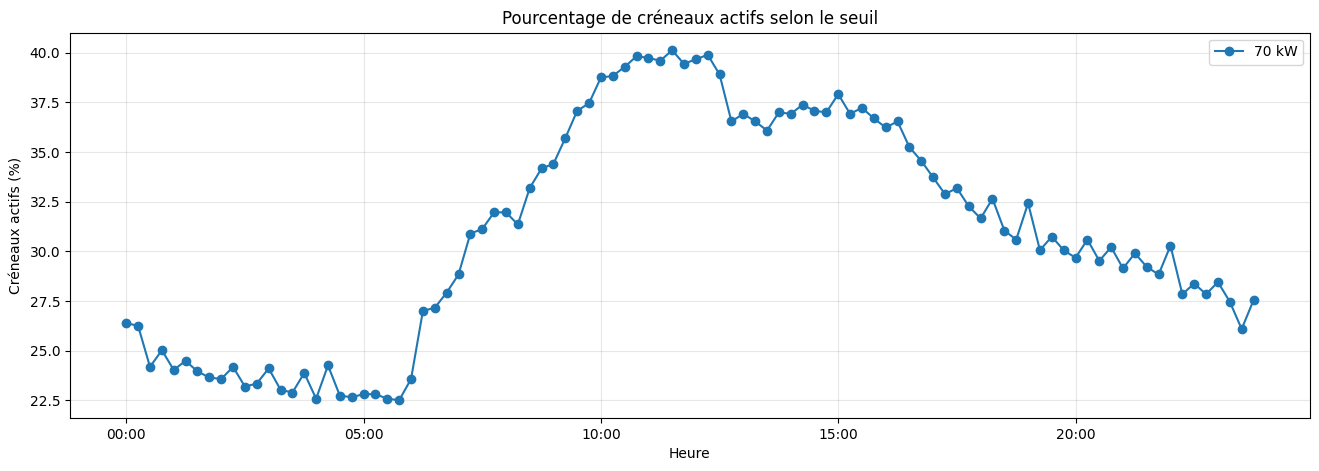

In [57]:
activity_by_threshold.plot(
    figsize=(16, 5),
    marker="o"
)

plt.title("Pourcentage de créneaux actifs selon le seuil")
plt.xlabel("Heure")
plt.ylabel("Créneaux actifs (%)")
plt.grid(alpha=0.3)
plt.show()

In [58]:
summary_global = pd.DataFrame({
    "compteur": ["EM_VIRTUAL"],
    "energie_totale_kwh": [
        clean["delta_ea_numeric"].sum()
    ],
    "energie_moyenne_par_creneau_kwh": [
        clean["delta_ea_numeric"].mean()
    ],
    "pmax_moyenne_kw": [
        clean["pmax_numeric"].mean()
    ],
    "pmax_mediane_kw": [
        clean["pmax_numeric"].median()
    ],
    "charge_base_5e_percentile_kw": [
        clean["pmax_numeric"].quantile(0.05)
    ],
    "pmax_max_kw": [
        clean["pmax_numeric"].max()
    ],
    "heure_pmax_max": [
        clean["pmax_numeric"].idxmax()
    ],
    "smax_max_kva": [
        clean["smax_kva"].max()
    ],
    "seuil_pic_90e_percentile_kw": [
        peak_threshold
    ],
    "duree_totale_pics_heures": [
        clean["is_peak"].sum() * 15 / 60
    ],
    "seuil_activite_important_kw": [
        30
    ],
    "duree_active_seuil_1kw_heures_moyenne": [
        daily_activity["duree_active_heures"].mean()
    ],
})

display(summary_global)

,compteur,energie_totale_kwh,energie_moyenne_par_creneau_kwh,pmax_moyenne_kw,pmax_mediane_kw,charge_base_5e_percentile_kw,pmax_max_kw,heure_pmax_max,smax_max_kva,seuil_pic_90e_percentile_kw,duree_totale_pics_heures,seuil_activite_important_kw,duree_active_seuil_1kw_heures_moyenne
0,EM_VIRTUAL,1877941.8,14.922302,59.659404,48.95,21.33,290.25,2025-09-01 14:30:00,301.17,108.51,3147.25,30,23.970084


In [59]:
period_summary = clean.groupby("period_type").agg(
    energie_totale_kwh=("delta_ea_numeric", "sum"),
    energie_moyenne_kwh=("delta_ea_numeric", "mean"),
    pmax_moyenne_kw=("pmax_numeric", "mean"),
    pmax_mediane_kw=("pmax_numeric", "median"),
    pmax_max_kw=("pmax_numeric", "max"),
    ecart_type_pmax_kw=("pmax_numeric", "std"),
    variance_pmax_kw=("pmax_numeric", "var"),
    nombre_creneaux=("pmax_numeric", "count"),
)

display(period_summary)

,energie_totale_kwh,energie_moyenne_kwh,pmax_moyenne_kw,pmax_mediane_kw,pmax_max_kw,ecart_type_pmax_kw,variance_pmax_kw,nombre_creneaux
period_type,,,,,,,,
Non ouvré,448235.0,12.517384,50.068736,37.79,258.88,30.497072,930.071427,35809
Ouvré,1429706.8,15.87875,63.473326,52.39,290.25,37.643249,1417.014183,90047


In [60]:
from pathlib import Path

REPORT_DIR = Path("/kaggle/working/phase1/reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

summary_global.to_csv(
    REPORT_DIR / "summary_global.csv",
    index=False
)

period_summary.to_csv(
    REPORT_DIR / "summary_by_period.csv"
)

season_summary.to_csv(
    REPORT_DIR / "summary_by_season.csv"
)

daily_activity.to_csv(
    REPORT_DIR / "daily_activity.csv"
)

peak_episodes.to_csv(
    REPORT_DIR / "peak_episodes.csv"
)

print("Tableaux sauvegardés dans :", REPORT_DIR)

Tableaux sauvegardés dans : /kaggle/working/phase1/reports


In [66]:
FIGURES_DIR = Path("/kaggle/working/phase1/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [67]:
plt.savefig(
    FIGURES_DIR / "nom_du_graphique.png",
    dpi=150,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [68]:
for path in sorted(Path("/kaggle/working/phase1").rglob("*")):
    if path.is_file():
        print(path)

/kaggle/working/phase1/figures/nom_du_graphique.png
/kaggle/working/phase1/quality_report.json
/kaggle/working/phase1/reports/daily_activity.csv
/kaggle/working/phase1/reports/peak_episodes.csv
/kaggle/working/phase1/reports/summary_by_period.csv
/kaggle/working/phase1/reports/summary_by_season.csv
/kaggle/working/phase1/reports/summary_global.csv
/kaggle/working/phase1/sinert_clean.parquet
/kaggle/working/phase1/window_index.parquet
